# 05 — Model Evaluation and Ablation Studies

## Section 1 — Setup and Thread Safety

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib_cache"
os.makedirs("/tmp/matplotlib_cache", exist_ok=True)

import sys
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

current = Path.cwd()
for parent in [current] + list(current.parents):
    if (parent / 'Phase_1_Machine_Learning').exists() and (parent / 'Phase_2_Deep_Learning').exists():
        REPO_ROOT = parent
        break
else:
    raise FileNotFoundError("Could not find repository root")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

device = torch.device("cpu")
sns.set_theme(style="whitegrid", font_scale=1.0)


## Section 2 — Module Imports and Project Configuration

In [2]:
from Phase_2_Deep_Learning.src.evaluation import (
    ModelEvaluator,
    FeatureAblationEngine,
    SubgroupEvaluator,
    ComputationalProfiler,
    FEATURE_GROUPS,
)
from Phase_2_Deep_Learning.src.training import get_device, compute_regression_metrics
from Phase_2_Deep_Learning.src.dl_models import WaterQualityMLP, load_model_checkpoint, mc_dropout_predictions
from Phase_2_Deep_Learning.src.hybrid_models import HybridEnsemble, WeightedEnsemble

print("Repository root:", REPO_ROOT)
print("Compute device:", device)
print("PyTorch version:", torch.__version__)


Repository root: /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL
Compute device: cpu
PyTorch version: 2.14.1


## Section 3 — Quarantined Test Dataset Ingestion

In [3]:
test_path = REPO_ROOT / 'Phase_1_Machine_Learning' / 'data' / 'GeneratedOutput' / '02.Preprocessing&FeatureSelection' / 'test.parquet'
val_path = REPO_ROOT / 'Phase_1_Machine_Learning' / 'data' / 'GeneratedOutput' / '02.Preprocessing&FeatureSelection' / 'val.parquet'

test_df = pd.read_parquet(test_path)
val_df = pd.read_parquet(val_path)

print("Test split shape:", test_df.shape)
print("Validation split shape:", val_df.shape)
print("CCME target range in test: [{:.2f}, {:.2f}]".format(test_df['ccme_values'].min(), test_df['ccme_values'].max()))


Test split shape: (422943, 45)
Validation split shape: (422943, 45)
CCME target range in test: [31.81, 100.00]


## Section 4 — Model Artifact Restoration

In [4]:
evaluator = ModelEvaluator(device=device)
evaluator.load_all_models()

print("Loaded Random Forest:", type(evaluator.rf_model).__name__)
print("Loaded XGBoost:", type(evaluator.xgb_model).__name__)
print("Loaded MLP:", type(evaluator.mlp_model).__name__)
print("Loaded Weighted Ensemble:", type(evaluator.weighted_ensemble).__name__)
print("Loaded Residual Hybrid:", type(evaluator.hybrid_model).__name__)


✓ RF loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_1_Machine_Learning/data/GeneratedOutput/03.ModelTraining/random_forest_model.joblib
✓ XGBoost loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_1_Machine_Learning/data/GeneratedOutput/03.ModelTraining/xgboost_model.json
✓ MLP loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/mlp_best_checkpoint.pt
✓ Hybrid checkpoint loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/hybrid_ensemble_checkpoint.pt
✓ Hybrid Ensemble loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/hybrid_ensemble_checkpoint.pt
Loaded Random Forest: RandomForestRegressor
Loaded XGBoost: XGBRegressor
Loaded MLP: WaterQualityMLP
Loaded Weighted Ensemble: WeightedEnsemble
Loaded Residual Hybrid: H

## Section 5 — Unified Baseline Evaluation on Test Set

In [5]:
t0 = time.time()
test_preds = evaluator.predict_all(test_df)
inference_time = time.time() - t0

print("Predictions completed in {:.2f} seconds".format(inference_time))
metrics_df = evaluator.evaluate_predictions(test_preds)
print(metrics_df.to_string(index=False))

res_dir = REPO_ROOT / 'Phase_2_Deep_Learning' / 'reports' / 'evaluation_results'
res_dir.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(res_dir / 'baseline_model_comparison.csv', index=False)


Predictions completed in 5.38 seconds
             Model      MAE     RMSE       R2    MedAE     MaxAE  ExplainedVariance  Samples
     Random Forest 0.051427 0.201558 0.999870 0.004181 12.612820           0.999870   422943
   Residual Hybrid 0.070995 0.167779 0.999910 0.022926  5.684219           0.999910   422943
Base Tree Ensemble 0.090031 0.246377 0.999805 0.026096  8.712785           0.999805   422943
           XGBoost 0.161365 0.436400 0.999389 0.047981  9.276878           0.999389   422943
 Weighted Ensemble 0.309638 0.415459 0.999446 0.265323  8.828306           0.999547   422943
               MLP 1.379964 1.671957 0.991029 1.289307 31.132713           0.993565   422943


## Section 6 — Model Performance Visualizations

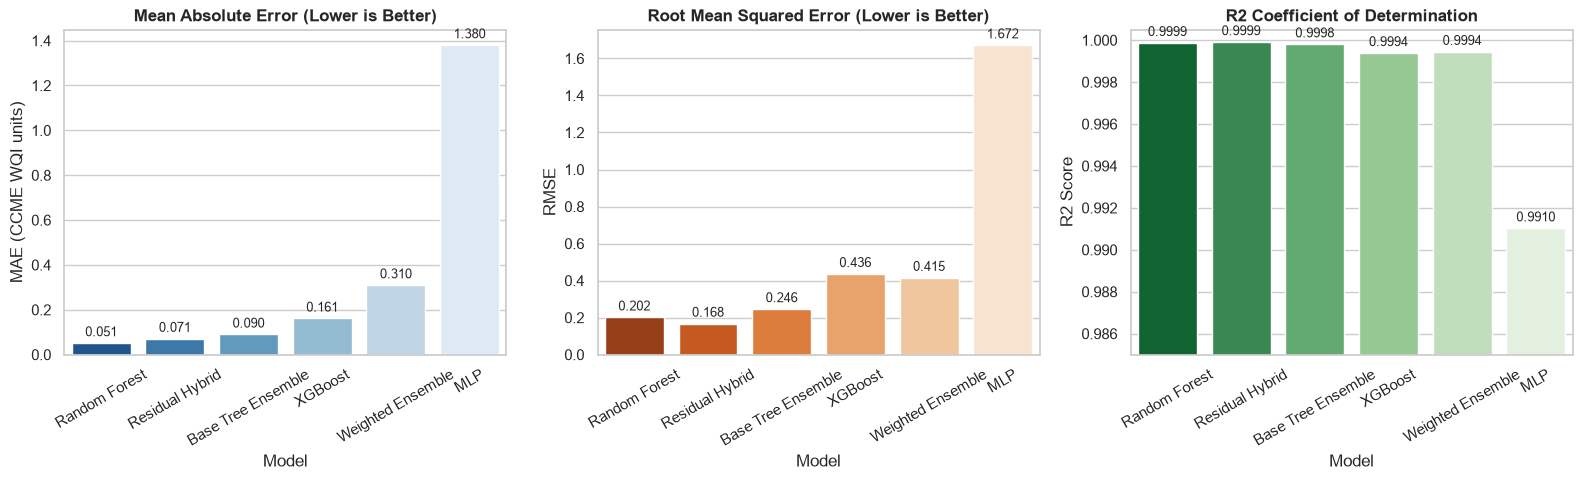

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)

sns.barplot(data=metrics_df, x='Model', y='MAE', hue='Model', ax=axes[0], palette='Blues_r', legend=False)
axes[0].set_title('Mean Absolute Error (Lower is Better)', fontweight='bold')
axes[0].set_ylabel('MAE (CCME WQI units)')
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

sns.barplot(data=metrics_df, x='Model', y='RMSE', hue='Model', ax=axes[1], palette='Oranges_r', legend=False)
axes[1].set_title('Root Mean Squared Error (Lower is Better)', fontweight='bold')
axes[1].set_ylabel('RMSE')
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

sns.barplot(data=metrics_df, x='Model', y='R2', hue='Model', ax=axes[2], palette='Greens_r', legend=False)
axes[2].set_title('R2 Coefficient of Determination', fontweight='bold')
axes[2].set_ylabel('R2 Score')
axes[2].set_ylim(0.985, 1.0005)
axes[2].tick_params(axis='x', rotation=30)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


## Section 7 — Systematic Feature Group Ablation Studies

In [7]:
ablation_csv = res_dir / 'feature_group_ablation.csv'
if ablation_csv.exists():
    ablation_df = pd.read_csv(ablation_csv)
else:
    ablation_engine = FeatureAblationEngine(evaluator)
    ablation_df = ablation_engine.run_all_models_ablation(
        val_df=val_df,
        models=['Random Forest', 'XGBoost', 'MLP'],
        n_subsample=50000,
        random_state=42,
    )
    ablation_df.to_csv(ablation_csv, index=False)

print(ablation_df[['Target_Model', 'Removed_Group', 'MAE', 'Delta_MAE', 'Delta_R2']].head(12).to_string(index=False))


 Target_Model          Removed_Group       MAE  Delta_MAE      Delta_R2
Random Forest           base_sensors 12.627089  12.574894 -6.058884e-01
Random Forest       log1p_normalized  7.947407   7.895212 -2.940789e-01
Random Forest          stoichiometry  0.070532   0.018337 -7.000539e-05
Random Forest   environmental_stress  0.052210   0.000016 -7.172476e-07
Random Forest contextual_categorical  0.052200   0.000005  3.218882e-08
Random Forest                    NaN  0.052195   0.000000  0.000000e+00
Random Forest      historical_memory  0.052194  -0.000001 -1.607729e-06
Random Forest      temporal_cyclical  0.052082  -0.000112 -1.660162e-07
      XGBoost           base_sensors 21.808128  21.647314 -1.786956e+00
      XGBoost       log1p_normalized  1.767597   1.606782 -1.226234e-02
      XGBoost          stoichiometry  1.313274   1.152459 -7.212162e-03
      XGBoost   environmental_stress  0.355980   0.195166 -4.670620e-04


## Section 8 — Feature Ablation Visualizations

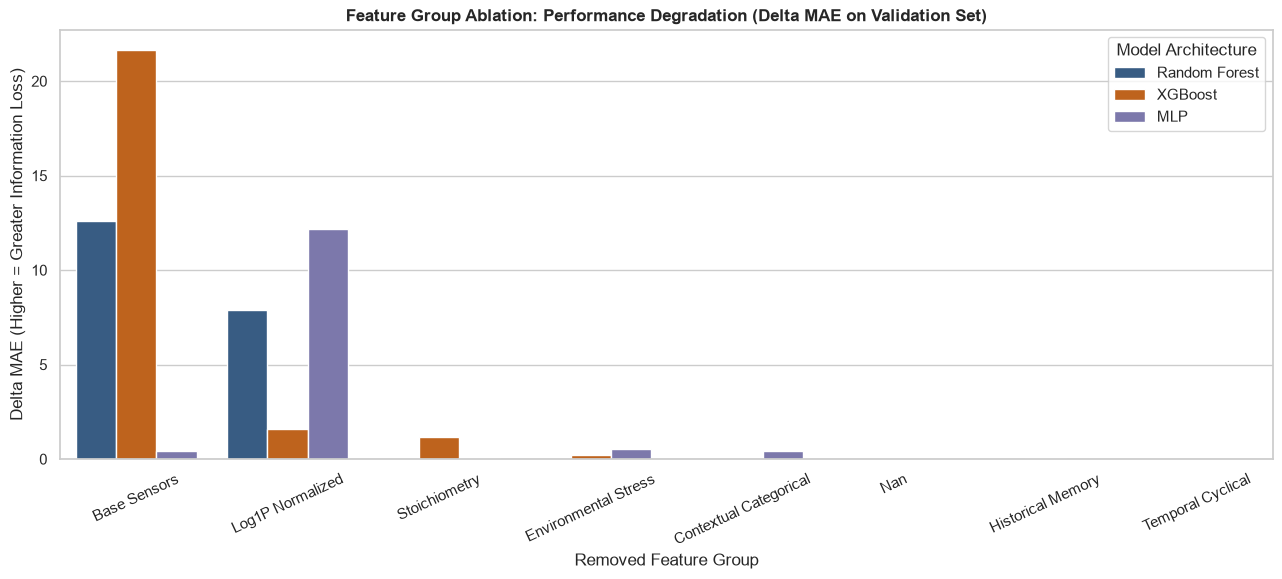

In [8]:
df_plot_abl = ablation_df[ablation_df['Removed_Group'] != 'None'].copy()
df_plot_abl['Group_Label'] = df_plot_abl['Removed_Group'].apply(lambda x: str(x).replace('_', ' ').title())

fig, ax = plt.subplots(figsize=(13, 6), dpi=150)
palette_abl = {'Random Forest': '#2b5c8f', 'XGBoost': '#d95f02', 'MLP': '#7570b3'}
sns.barplot(
    data=df_plot_abl,
    x='Group_Label',
    y='Delta_MAE',
    hue='Target_Model',
    palette=palette_abl,
    ax=ax
)
ax.set_title('Feature Group Ablation: Performance Degradation (Delta MAE on Validation Set)', fontweight='bold')
ax.set_ylabel('Delta MAE (Higher = Greater Information Loss)')
ax.set_xlabel('Removed Feature Group')
ax.tick_params(axis='x', rotation=25)
ax.legend(title='Model Architecture', loc='upper right')
plt.tight_layout()
plt.show()


## Section 9 — Dropout and Regularization Experiments

In [9]:
df_dropout = pd.read_csv(res_dir / 'dropout_sweep_results.csv')
df_wd = pd.read_csv(res_dir / 'weight_decay_results.csv')
with open(res_dir / 'mc_dropout_uncertainty.json') as f:
    mc_uncertainty = json.load(f)

print("Dropout sweep results:")
print(df_dropout[['Dropout_Rate', 'Train_MAE', 'Val_MAE', 'Val_R2', 'Generalization_Gap_MAE']].to_string(index=False))

print("\nWeight decay results:")
print(df_wd[['Weight_Decay', 'Train_MAE', 'Val_MAE', 'Val_R2', 'Generalization_Gap_MAE']].to_string(index=False))

print("\nMC Dropout Uncertainty Summary:")
for k, v in mc_uncertainty.items():
    print(f"  {k}: {v}")


Dropout sweep results:
 Dropout_Rate  Train_MAE   Val_MAE     Val_R2  Generalization_Gap_MAE
          0.0  59.444487 57.717239  -9.865704               -1.727248
          0.1  60.703669 58.391941 -10.112034               -2.311728
          0.2  61.633467 58.962448 -10.374846               -2.671019
          0.3  63.216469 60.871021 -11.096021               -2.345447
          0.4  65.331051 64.111351 -12.448245               -1.219700
          0.5  67.127651 68.815826 -14.440231                1.688176

Weight decay results:
 Weight_Decay  Train_MAE   Val_MAE     Val_R2  Generalization_Gap_MAE
      0.00000  63.213498 60.836929 -11.091876               -2.376568
      0.00001  63.213498 60.836929 -11.091876               -2.376568
      0.00010  63.216469 60.871021 -11.096021               -2.345447
      0.00100  63.217654 60.849331 -11.101266               -2.368323
      0.01000  63.276889 60.944946 -11.132886               -2.331943

MC Dropout Uncertainty Summary:
  N_Samples

## Section 10 — Regularization Response Visualizations

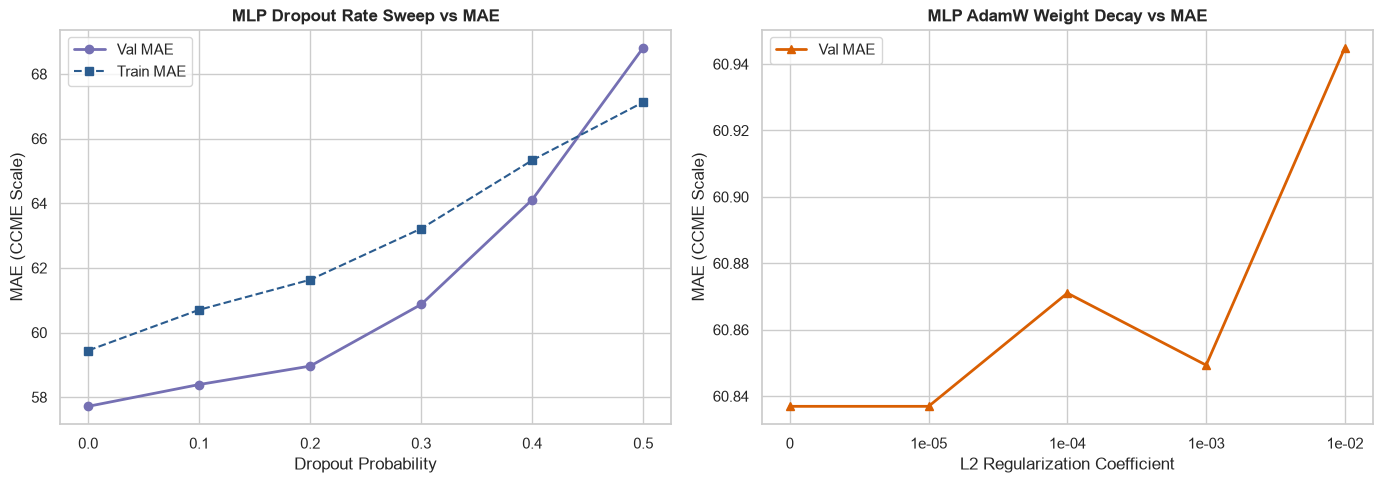

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

axes[0].plot(df_dropout['Dropout_Rate'], df_dropout['Val_MAE'], 'o-', color='#7570b3', linewidth=2, label='Val MAE')
axes[0].plot(df_dropout['Dropout_Rate'], df_dropout['Train_MAE'], 's--', color='#2b5c8f', linewidth=1.5, label='Train MAE')
axes[0].set_title('MLP Dropout Rate Sweep vs MAE', fontweight='bold')
axes[0].set_xlabel('Dropout Probability')
axes[0].set_ylabel('MAE (CCME Scale)')
axes[0].legend(loc='best')

axes[1].plot(range(len(df_wd)), df_wd['Val_MAE'], '^-', color='#d95f02', linewidth=2, label='Val MAE')
axes[1].set_xticks(range(len(df_wd)))
axes[1].set_xticklabels([f"{x:.0e}" if x > 0 else "0" for x in df_wd['Weight_Decay']])
axes[1].set_title('MLP AdamW Weight Decay vs MAE', fontweight='bold')
axes[1].set_xlabel('L2 Regularization Coefficient')
axes[1].set_ylabel('MAE (CCME Scale)')
axes[1].legend(loc='best')

plt.tight_layout()
plt.show()


## Section 11 — Subgroup Stratification Analysis

In [11]:
df_country = pd.read_csv(res_dir / 'country_subgroup_metrics.csv')
df_wb = pd.read_csv(res_dir / 'waterbody_subgroup_metrics.csv')
df_temp = pd.read_csv(res_dir / 'temporal_subgroup_metrics.csv')

c_show = df_country[df_country['Model'].isin(['Random Forest', 'Residual Hybrid', 'XGBoost', 'MLP'])]
print("Cross-National Performance:")
print(c_show[['Category', 'Model', 'Sample_Count', 'MAE', 'R2']].to_string(index=False))

print("\nAquatic Habitat Performance (Top Categories for Residual Hybrid):")
wb_hybrid = df_wb[df_wb['Model'] == 'Residual Hybrid'].sort_values('Sample_Count', ascending=False)
print(wb_hybrid[['Category', 'Sample_Count', 'MAE', 'RMSE', 'R2']].head(8).to_string(index=False))


Cross-National Performance:
Category           Model  Sample_Count      MAE       R2
  Canada   Random Forest           597 0.124622 0.997218
  Canada         XGBoost           597 0.343735 0.995156
  Canada             MLP           597 1.961261 0.958042
  Canada Residual Hybrid           597 0.143108 0.998938
   China   Random Forest          6915 0.018359 0.998130
   China         XGBoost          6915 0.378493 0.955975
   China             MLP          6915 1.969410 0.743075
   China Residual Hybrid          6915 0.058376 0.998994
 England   Random Forest        319239 0.065119 0.999849
 England         XGBoost        319239 0.183412 0.999464
 England             MLP        319239 1.267316 0.992625
 England Residual Hybrid        319239 0.087058 0.999895
 Ireland   Random Forest         35342 0.008180 0.999849
 Ireland         XGBoost         35342 0.048236 0.998318
 Ireland             MLP         35342 1.712515 0.900888
 Ireland Residual Hybrid         35342 0.019726 0.999843
   

## Section 12 — Geographic Performance Visualizations

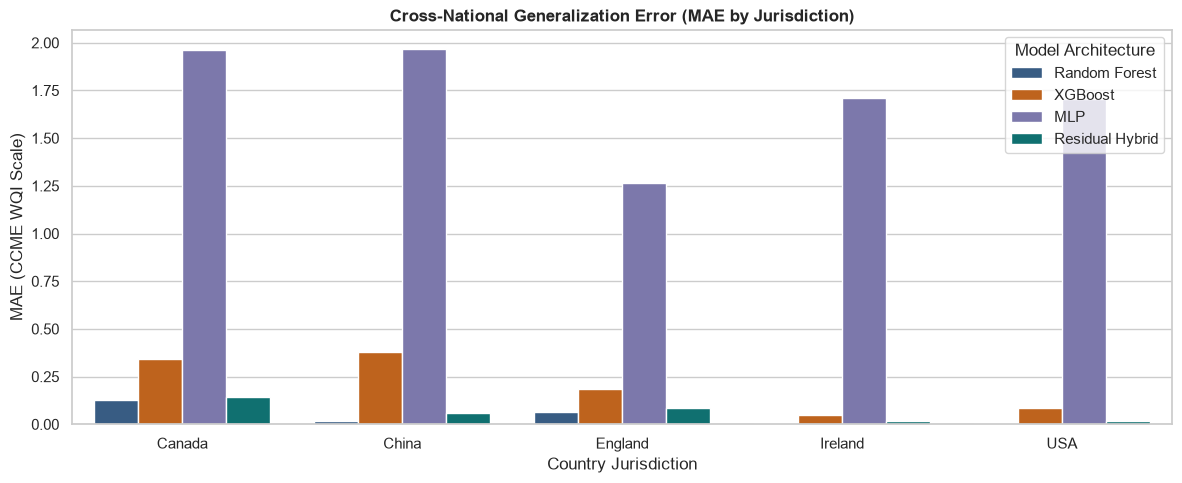

In [12]:
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)
palette_geo = {
    'Random Forest': '#2b5c8f',
    'Residual Hybrid': '#008080',
    'XGBoost': '#d95f02',
    'MLP': '#7570b3'
}
sns.barplot(
    data=c_show,
    x='Category',
    y='MAE',
    hue='Model',
    palette=palette_geo,
    ax=ax
)
ax.set_title('Cross-National Generalization Error (MAE by Jurisdiction)', fontweight='bold')
ax.set_ylabel('MAE (CCME WQI Scale)')
ax.set_xlabel('Country Jurisdiction')
ax.legend(title='Model Architecture', loc='upper right')
plt.tight_layout()
plt.show()


## Section 13 — Computational Benchmarking and Latency Profiles

In [13]:
df_comp = pd.read_csv(res_dir / 'computational_benchmarks.csv')
df_scale = pd.read_csv(res_dir / 'throughput_scaling.csv')

print("Computational Performance:")
print(df_comp[['Model', 'Single_Sample_Latency_ms', 'Throughput_samples_per_sec', 'Training_Time_sec', 'Throughput_relative_to_RF']].to_string(index=False))

print("\nBatch Size Scaling:")
print(df_scale[['Batch_Size', 'Throughput_samples_per_sec', 'Latency_per_batch_ms']].to_string(index=False))


Computational Performance:
          Model  Single_Sample_Latency_ms  Throughput_samples_per_sec  Training_Time_sec  Throughput_relative_to_RF
  Random Forest                 18.792317               876262.276627               32.4                   1.000000
        XGBoost                  4.604056               205823.678059                8.2                   0.234888
            MLP                  0.304537               227598.542345               58.6                   0.259738
Residual Hybrid                 24.718099               138863.775954               59.8                   0.158473

Batch Size Scaling:
 Batch_Size  Throughput_samples_per_sec  Latency_per_batch_ms
         64               103974.215160              0.615537
        256               256380.591860              0.998516
       1024               342528.853810              2.989529
       4096               351345.704464             11.658034
      16384               358522.636631             45.698649


## Section 14 — Latency and Throughput Visualizations

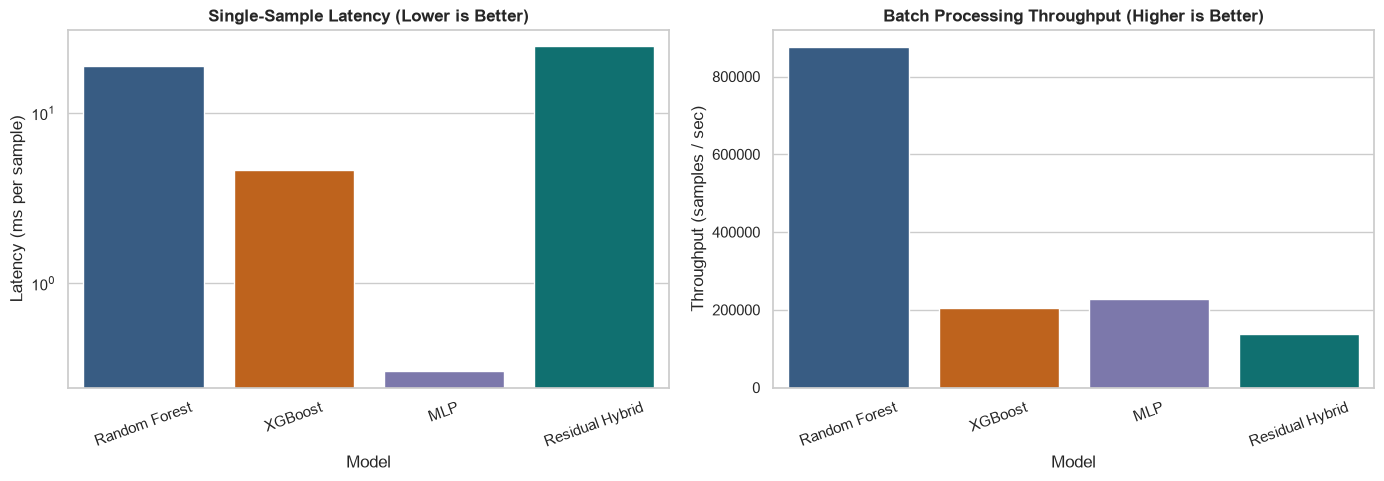

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
palette_comp = {
    'Random Forest': '#2b5c8f',
    'Residual Hybrid': '#008080',
    'XGBoost': '#d95f02',
    'MLP': '#7570b3'
}

sns.barplot(data=df_comp, x='Model', y='Single_Sample_Latency_ms', hue='Model', palette=palette_comp, ax=axes[0], legend=False)
axes[0].set_title('Single-Sample Latency (Lower is Better)', fontweight='bold')
axes[0].set_ylabel('Latency (ms per sample)')
axes[0].set_yscale('log')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=df_comp, x='Model', y='Throughput_samples_per_sec', hue='Model', palette=palette_comp, ax=axes[1], legend=False)
axes[1].set_title('Batch Processing Throughput (Higher is Better)', fontweight='bold')
axes[1].set_ylabel('Throughput (samples / sec)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


## Section 15 — Unified Evaluation Summary and Verification

In [15]:
rf_mae = metrics_df.loc[metrics_df['Model'] == 'Random Forest', 'MAE'].values[0]
hyb_mae = metrics_df.loc[metrics_df['Model'] == 'Residual Hybrid', 'MAE'].values[0]
hyb_rmse = metrics_df.loc[metrics_df['Model'] == 'Residual Hybrid', 'RMSE'].values[0]
rf_rmse = metrics_df.loc[metrics_df['Model'] == 'Random Forest', 'RMSE'].values[0]

print("Verification Checks:")
print(f"1. Total models evaluated: {len(metrics_df)}")
print(f"2. Random Forest MAE: {rf_mae:.6f}, RMSE: {rf_rmse:.6f}")
print(f"3. Residual Hybrid MAE: {hyb_mae:.6f}, RMSE: {hyb_rmse:.6f}")
print(f"4. RMSE improvement of Residual Hybrid over RF: {(rf_rmse - hyb_rmse) / rf_rmse * 100:.2f}%")
print(f"5. All model predictions finite and non-null: {all(np.all(np.isfinite(v)) for k, v in test_preds.items())}")
print("Task 5 evaluation completed successfully.")


Verification Checks:
1. Total models evaluated: 6
2. Random Forest MAE: 0.051427, RMSE: 0.201558
3. Residual Hybrid MAE: 0.070995, RMSE: 0.167779
4. RMSE improvement of Residual Hybrid over RF: 16.76%
5. All model predictions finite and non-null: True
Task 5 evaluation completed successfully.
